# 01 — Data Exploration: PNW dataset (Phase 1)

**Dataset:** Curated Pacific Northwest AI-ready Seismic Dataset (Ni et al., 2023, *Seismica* 2(1),
doi:10.26443/seismica.v2i1.368; CC BY 4.0). Selection rationale: `PROJECT_CONTEXT.md` → *DATASET SELECTED*.

**Purpose:** understand whether this data can support the research question (multi-station,
three-component, earthquake vs anthropogenic, OOD). This notebook **measures and inspects only** —
no preprocessing pipeline, no model, no results.

**Evidence labels used below:** **Observed** (measured here) · **Inferred** (interpretation of
observations) · **Documented** (stated by the dataset authors) · **Unknown**.

**Scope of waveform statistics:** catalogue statistics use the *full* metadata (all events).
Waveform-level inspection uses the Phase 1 *exploration subsets* (seeded, event-complete samples;
see `PROVENANCE.json`) — they are **not** class-balanced training data.

**Running elsewhere (e.g. Colab + Google Drive):** set `SEISMIC_DATA_ROOT` in the setup cell; no
path in this notebook is machine-specific.

## 0. Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Optional: Google Colab with Google Drive -------------------------------------------
# from google.colab import drive; drive.mount("/content/drive")
# os.environ["SEISMIC_DATA_ROOT"] = "/content/drive/MyDrive/seismic-data"
# -----------------------------------------------------------------------------------------

def find_project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "config.yaml").is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the project (configs/config.yaml not found).")

PROJECT_ROOT = find_project_root()

from seismic_ml.config import load_config
from seismic_ml.paths import resolve_paths
from seismic_ml.data import pnw
from seismic_ml.data.loader import load_collection_metadata, waveform_path
from seismic_ml.data.seisbench_format import SeisBenchWaveformStore
from seismic_ml.data import inspection
from seismic_ml.utils.visualization import plot_event_waveforms, plot_station_map

CONFIG = load_config(PROJECT_ROOT / "configs" / "config.yaml")
DATA_CFG = CONFIG["data"]
PATHS = resolve_paths(CONFIG, project_root=PROJECT_ROOT)      # --data-root / env / config
RAW = PATHS.dataset_raw_dir(DATA_CFG)
SEED = DATA_CFG["dataset"]["exploration_subset"]["seed"]

def show(path: Path) -> str:
    """Display a path without leaking machine-specific prefixes."""
    try:
        return path.resolve().relative_to(PROJECT_ROOT).as_posix()
    except ValueError:
        return f"<SEISMIC_DATA_ROOT>/{path.resolve().relative_to(PATHS.data_root).as_posix()}"

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print("raw data dir:", show(RAW)); print("seed:", SEED)

raw data dir: data/raw/pnw
seed: 42


In [2]:
cc = load_collection_metadata(RAW, DATA_CFG, "comcat")   # full ComCat metadata
ex = load_collection_metadata(RAW, DATA_CFG, "exotic")   # full exotic metadata
cc_store = SeisBenchWaveformStore(waveform_path(RAW, DATA_CFG, "comcat"))
ex_store = SeisBenchWaveformStore(waveform_path(RAW, DATA_CFG, "exotic"))
for name, store in [("comcat", cc_store), ("exotic", ex_store)]:
    kind = "exploration subset" if store.is_subset else "full file"
    n = len(store.available_trace_names()) if store.is_subset else "all"
    print(f"{name}: waveforms from {show(store.path)} ({kind}, traces stored: {n}); component order {''.join(store.component_order)}")
print("ComCat metadata columns:", list(cc.columns))
print("Exotic metadata columns:", list(ex.columns))

comcat: waveforms from data/raw/pnw/subsets/comcat_exploration_subset.hdf5 (exploration subset, traces stored: 4019); component order ENZ
exotic: waveforms from data/raw/pnw/subsets/exotic_exploration_subset.hdf5 (exploration subset, traces stored: 1133); component order ENZ
ComCat metadata columns: ['event_id', 'source_origin_time', 'source_latitude_deg', 'source_longitude_deg', 'source_type', 'source_depth_km', 'preferred_source_magnitude', 'preferred_source_magnitude_type', 'preferred_source_magnitude_uncertainty', 'source_depth_uncertainty_km', 'source_horizontal_uncertainty_km', 'station_network_code', 'station_channel_code', 'station_code', 'station_location_code', 'station_latitude_deg', 'station_longitude_deg', 'station_elevation_m', 'trace_name', 'trace_sampling_rate_hz', 'trace_start_time', 'trace_S_arrival_sample', 'trace_P_arrival_sample', 'trace_S_arrival_uncertainty_s', 'trace_P_arrival_uncertainty_s', 'trace_P_polarity', 'trace_S_onset', 'trace_P_onset', 'trace_snr_db', 

## 1. Dataset overview (full metadata)

In [3]:
def overview(m, name):
    sid = m.station_network_code + "." + m.station_code
    return pd.Series({"events": m.event_id.nunique(), "waveform records (traces)": len(m),
                      "unique stations (NET.STA)": sid.nunique(), "networks": m.station_network_code.nunique()},
                     name=name)
pd.concat([overview(cc, "comcat"), overview(ex, "exotic")], axis=1)

,comcat,exotic
events,46054,5657
waveform records (traces),178939,9267
unique stations (NET.STA),639,146
networks,9,6


In [4]:
print("ComCat — `source_type` (ComCat category)"); display(inspection.label_counts(cc, "source_type"))
print("ComCat — `source_type_pnsn_label` (PNSN analyst label)"); display(inspection.label_counts(cc, "source_type_pnsn_label"))
print("Exotic — `source_type`"); display(inspection.label_counts(ex, "source_type"))

ComCat — `source_type` (ComCat category)


,events,traces
source_type,,
earthquake,39716,163064
explosion,6338,15875


ComCat — `source_type_pnsn_label` (PNSN analyst label)


,events,traces
source_type_pnsn_label,,
eq,39366,161942
px,6362,16076
lf,265,758
ex,30,63
su,24,72
qb,4,21
sn,2,4
uk,1,3


Exotic — `source_type`


,events,traces
source_type,,
surface event,5425,8912
thunder,120,146
sonic boom,111,206
plane crash,1,3


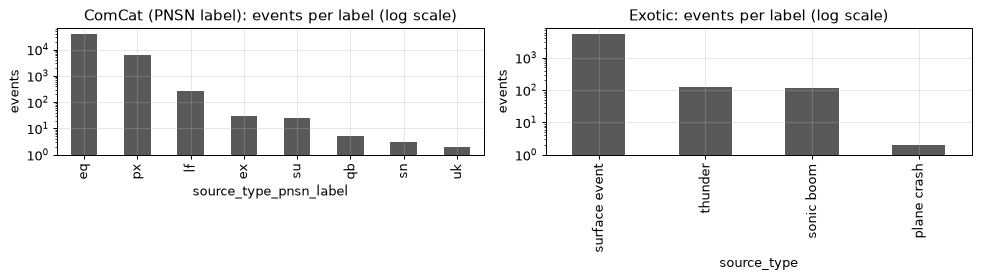

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (m, col, title) in zip(axes, [(cc, "source_type_pnsn_label", "ComCat (PNSN label)"), (ex, "source_type", "Exotic")]):
    counts = inspection.label_counts(m, col)["events"]
    counts.plot.bar(ax=ax, color="0.35", log=True); ax.set_title(f"{title}: events per label (log scale)"); ax.set_ylabel("events")
fig.tight_layout()

## 2. Label analysis

Label codes (sources in `PROJECT_CONTEXT.md` → *DATASET SELECTED*): `eq` earthquake; `px` probable
explosion (analyst judgement: strong P + location near known quarries; mostly quarry blasts);
`ex` explosion; `qb` quarry blast; `lf` low-frequency event (volcanic / glacial sources);
`su` surface event (mass movements, mostly near volcanoes); `sn` sonic boom; `uk` unknown
(meaning inferred from the code name — not verified in a PNSN document).

**Documented:** ComCat merges "earthquake", "slow earthquake" and "long period volcanic earthquake"
into `earthquake`, and "explosion", "shot", "probable explosion" into `explosion`; the dataset
README recommends preferring the PNSN label when the two disagree.

In [6]:
agree = inspection.label_agreement(cc, "source_type", "source_type_pnsn_label")
display(agree)
conflict = {("earthquake", "px"), ("explosion", "eq")}
n_conflict = sum(agree.loc[a, b] for a, b in conflict if a in agree.index and b in agree.columns)
print(f"Observed: {n_conflict} events where ComCat and PNSN disagree on earthquake vs explosion.")
print(f"Observed: ComCat 'earthquake' also contains PNSN labels: {sorted(set(agree.columns[agree.loc['earthquake'] > 0]) - {'eq'})}")

source_type_pnsn_label,eq,ex,lf,px,qb,sn,su,uk
source_type,,,,,,,,
earthquake,39355,0,265,69,0,2,24,1
explosion,11,30,0,6293,4,0,0,0


Observed: 80 events where ComCat and PNSN disagree on earthquake vs explosion.
Observed: ComCat 'earthquake' also contains PNSN labels: ['lf', 'px', 'sn', 'su', 'uk']


In [7]:
labels_cfg = DATA_CFG["labels"]
events = cc.groupby("event_id").source_type_pnsn_label.first()
role = events.map(lambda l: labels_cfg["class_map"].get(l) or ("OOD candidate" if l in labels_cfg["ood_labels"]["comcat"]
                  else "excluded" if l in labels_cfg["excluded_labels"]["comcat"] else "UNMAPPED"))
print("PROPOSED roles of ComCat events (Decisions 010/011 — proposal, not yet used by any code):")
display(pd.crosstab(events, role, margins=True))
assert (role != "UNMAPPED").all(), "every PNSN label must have an explicit role"

PROPOSED roles of ComCat events (Decisions 010/011 — proposal, not yet used by any code):


source_type_pnsn_label,OOD candidate,anthropogenic,earthquake,excluded,All
source_type_pnsn_label,,,,,
eq,0,0,39366,0,39366
ex,0,30,0,0,30
lf,265,0,0,0,265
px,0,6362,0,0,6362
qb,0,4,0,0,4
sn,2,0,0,0,2
su,24,0,0,0,24
uk,0,0,0,1,1
All,291,6396,39366,1,46054


## 3. Multi-station coverage

The graph model needs several stations per event. One metadata row = one station recording of one
event; **Observed:** `(event_id, NET.STA)` is unique, so *traces per event = stations per event*.

In [8]:
dup = cc.duplicated(["event_id", "station_network_code", "station_code"]).sum() + ex.duplicated(["event_id", "station_network_code", "station_code"]).sum()
print("duplicate (event, station) rows:", dup)
t_cc = inspection.station_count_table(cc, "source_type_pnsn_label")
t_ex = inspection.station_count_table(ex, "source_type")
print("Events per stations-per-event bin — ComCat by PNSN label"); display(t_cc)
print("Row-normalised (fraction of each label's events)"); display(t_cc.div(t_cc.sum(axis=1), axis=0).round(3))
print("Exotic by label"); display(t_ex)

duplicate (event, station) rows: 0


Events per stations-per-event bin — ComCat by PNSN label


,1,2,3,4+
source_type_pnsn_label,,,,
eq,6867,6637,6245,19617
ex,14,8,3,5
lf,73,63,51,78
px,2137,1691,1139,1395
qb,0,0,1,3
sn,0,2,0,0
su,5,8,5,6
uk,0,0,1,0


Row-normalised (fraction of each label's events)


,1,2,3,4+
source_type_pnsn_label,,,,
eq,0.174,0.169,0.159,0.498
ex,0.467,0.267,0.100,0.167
lf,0.275,0.238,0.192,0.294
px,0.336,0.266,0.179,0.219
qb,0.000,0.000,0.250,0.750
sn,0.000,1.000,0.000,0.000
su,0.208,0.333,0.208,0.250
uk,0.000,0.000,1.000,0.000


Exotic by label


,1,2,3,4+
source_type,,,,
plane crash,0,0,1,0
sonic boom,73,9,10,19
surface event,4214,489,192,530
thunder,105,8,4,3


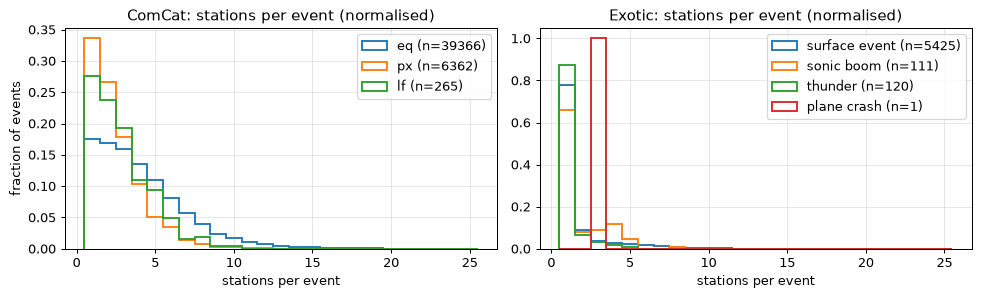

In [9]:
n_cc = inspection.stations_per_event(cc); lab_cc = cc.groupby("event_id").source_type_pnsn_label.first()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.arange(0.5, 26.5, 1)
for lab, color in [("eq", "tab:blue"), ("px", "tab:orange"), ("lf", "tab:green")]:
    axes[0].hist(n_cc[lab_cc == lab], bins=bins, density=True, histtype="step", lw=1.5, color=color, label=f"{lab} (n={int((lab_cc == lab).sum())})")
axes[0].set(xlabel="stations per event", ylabel="fraction of events", title="ComCat: stations per event (normalised)"); axes[0].legend()
n_ex = inspection.stations_per_event(ex); lab_ex = ex.groupby("event_id").source_type.first()
for lab in lab_ex.unique():
    axes[1].hist(n_ex[lab_ex == lab], bins=bins, density=True, histtype="step", lw=1.5, label=f"{lab} (n={int((lab_ex == lab).sum())})")
axes[1].set(xlabel="stations per event", title="Exotic: stations per event (normalised)"); axes[1].legend()
fig.tight_layout()

**Observed:** explosion (`px`) events have systematically fewer stations than earthquakes, and most
exotic events are single-station. **Inferred:** station count is a potential *shortcut* for a
graph/set model (fewer nodes ⇒ "explosion"); Phase 2+ must control for it (e.g. evaluate per
station-count bin, or sub-sample stations). **Documented cause (partial):** ComCat traces were only
kept where both P and S were picked.

## 4. Sampling information and windows

In [10]:
q = {c: inspection.metadata_quality(m, origin_offset_s=-50.0 if c == "comcat" else None) for c, m in [("comcat", cc), ("exotic", ex)]}
for c in q:
    print(f"{c}: sampling rates {q[c]['sampling_rates_hz']} Hz | samples per trace {q[c]['samples_per_trace']} | picks {q[c]['picks']}")
print("comcat trace_start - origin (s):", q["comcat"]["start_minus_origin_s"])

comcat: sampling rates [100.0] Hz | samples per trace [15001] | picks {'p_missing': 0, 's_missing': 0, 's_before_p': 0, 's_equals_p': 0}
exotic: sampling rates [100.0] Hz | samples per trace [18001] | picks {'p_missing': 120, 's_missing': 8607, 's_before_p': 0, 's_equals_p': 26}
comcat trace_start - origin (s): {'expected': -50.0, 'n_deviating_gt_0p01s': 0, 'min': -50.0, 'max': -49.99}


exotic traces with P exactly at 70.00 s: 0.9871


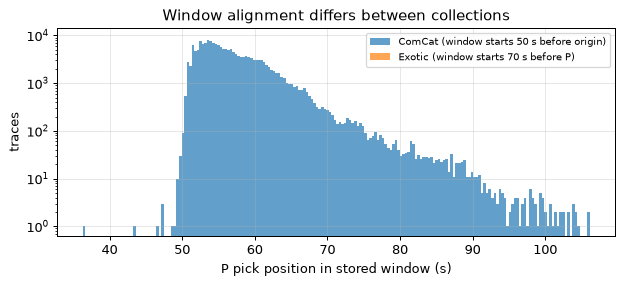

In [11]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(cc.trace_P_arrival_sample / 100, bins=200, alpha=0.7, label="ComCat (window starts 50 s before origin)")
ax.hist(ex.trace_P_arrival_sample.dropna() / 100, bins=200, alpha=0.7, label="Exotic (window starts 70 s before P)")
ax.set(xlabel="P pick position in stored window (s)", ylabel="traces", yscale="log", title="Window alignment differs between collections")
ax.legend(fontsize=8)
print("exotic traces with P exactly at 70.00 s:", round(float((ex.trace_P_arrival_sample == 7000).mean()), 4))

**Observed:** ComCat windows are 150.01 s and origin-aligned (P position varies with distance);
exotic windows are 180.01 s and pick-aligned (P at exactly 70 s in ~99 % of traces).
**Inferred — important:** any model fed the stored windows could separate exotic (OOD) from ComCat
events by *pick position or window length alone*. Phase 2 must apply one common windowing rule
(e.g. P-aligned, fixed length) to every collection before OOD experiments are meaningful.

## 5. Three-component validation

What the files contain (**Observed**): arrays `[3, T]` in order `ENZ` (`/data_format/component_order`);
channel metadata keeps only the *band + instrument* code (`EH`, `BH`, `HH`), not the component codes.

In [12]:
mc = inspection.missing_components(cc, cc_store.component_order).replace("", "none")
display(pd.crosstab(cc.station_channel_code, mc, margins=True).rename_axis(index="band code", columns="missing (from NaN SNR)"))
display(pd.crosstab(cc.station_channel_code, cc.trace_missing_channel, normalize="index").round(3).rename_axis(columns="trace_missing_channel"))

missing (from NaN SNR),E,EN,EZ,N,NZ,Z,none,All
band code,,,,,,,,
BH,0,5,0,3,0,25,54009,54042
EH,9,49829,0,0,0,3282,45265,98385
HH,42,74,6,2,1,200,26187,26512
All,51,49908,6,5,1,3507,125461,178939


trace_missing_channel,0,1,2
station_channel_code,,,
BH,0.999,0.001,0.000
EH,0.460,0.033,0.506
HH,0.988,0.009,0.003


In [13]:
wq = inspection.waveform_quality_table(cc, cc_store)          # measured on the ComCat exploration subset
per_trace = wq.groupby("trace_name").all_zero.sum().rename("zero_components").to_frame().join(cc.set_index("trace_name")[["trace_missing_channel", "station_channel_code"]])
print("subset traces measured:", len(per_trace))
display(pd.crosstab(per_trace.zero_components, per_trace.trace_missing_channel).rename_axis(index="all-zero components (measured)", columns="trace_missing_channel flag"))
print("which components are all-zero (subset):"); display(wq[wq.all_zero].component.value_counts())

subset traces measured: 4019


trace_missing_channel flag,0,1,2
all-zero components (measured),,,
0,2897,0,0
1,0,69,0
2,0,0,1053


which components are all-zero (subset):


component
E    1054
N    1053
Z      68
Name: count, dtype: int64

**Observed:** vertical-only instruments (mostly `EH`, short-period) appear with both horizontals
filled with zeros; the `trace_missing_channel` flag and the NaN SNR entries identify them.
**Documented:** zero-filling was done by the curators. **Unknown:** whether horizontal components
of each instrument were physically North/East or rotated `1`/`2` components mapped to `N`/`E`
(the original component codes are not in the metadata) — do not assume physical equivalence;
check station orientation metadata (FDSN StationXML) in Phase 2 if horizontal directions matter.
Amplitudes are in **counts** (no instrument response removed; documented), so amplitude scales
differ between instrument types:

In [14]:
peaks = wq[~wq.all_zero].merge(cc[["trace_name", "station_channel_code"]], on="trace_name")
display(peaks.groupby("station_channel_code").peak_abs.describe(percentiles=[.05, .5, .95]).round(1))

,count,mean,std,min,5%,50%,95%,max
station_channel_code,,,,,,,,
BH,4038.0,6693.8,57224.7,15.4,177.1,1051.8,16996.6,1974607.7
EH,3999.0,1093.7,4144.9,3.3,39.8,264.8,4170.5,165988.8
HH,1845.0,5342.7,28151.9,24.6,164.1,865.0,14679.9,565082.4


## 6. Station distribution

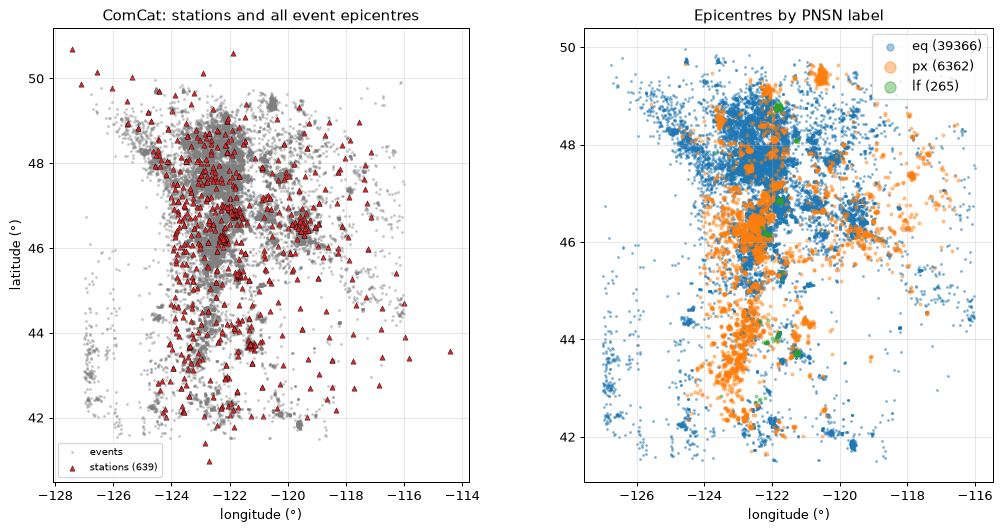

In [15]:
first = cc.drop_duplicates(["station_network_code", "station_code"])
stations = [pnw.row_to_station(r) for r in first.to_dict("records")]
ev_ll = cc.groupby("event_id")[["source_latitude_deg", "source_longitude_deg"]].first().to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_station_map(stations, events_lat_lon=ev_ll, ax=axes[0]); axes[0].set_title("ComCat: stations and all event epicentres")
ev_cls = cc.groupby("event_id").agg(lat=("source_latitude_deg", "first"), lon=("source_longitude_deg", "first"), lab=("source_type_pnsn_label", "first"))
for lab, color in [("eq", "tab:blue"), ("px", "tab:orange"), ("lf", "tab:green")]:
    sub = ev_cls[ev_cls.lab == lab]
    axes[1].scatter(sub.lon, sub.lat, s=2 if lab == "eq" else 5, alpha=0.4, color=color, label=f"{lab} ({len(sub)})", rasterized=True)
axes[1].set_aspect(1 / np.cos(np.deg2rad(46))); axes[1].legend(markerscale=4); axes[1].set(title="Epicentres by PNSN label", xlabel="longitude (°)")
fig.tight_layout()

In [16]:
sid_cc = set(cc.station_network_code + "." + cc.station_code); sid_ex = set(ex.station_network_code + "." + ex.station_code)
print(f"stations: ComCat {len(sid_cc)}, exotic {len(sid_ex)}, exotic stations also in ComCat {len(sid_ex & sid_cc)}")
nets = pd.concat([cc.station_network_code.value_counts(normalize=True).rename("comcat"), ex.station_network_code.value_counts(normalize=True).rename("exotic")], axis=1).fillna(0).round(3)
display(nets.head(8))
coords = cc.assign(sid=cc.station_network_code + "." + cc.station_code).groupby("sid")[["station_latitude_deg", "station_longitude_deg"]].nunique().max(axis=1)
print("sites whose coordinates change over time (use per-row coordinates):", int((coords > 1).sum()))

stations: ComCat 639, exotic 146, exotic stations also in ComCat 143


,comcat,exotic
station_network_code,,
UW,0.517,0.61
PB,0.227,0.05
CC,0.127,0.337
TA,0.054,0.0
CN,0.033,0.0
UO,0.02,0.003
US,0.018,0.0
HW,0.004,0.0


sites whose coordinates change over time (use per-row coordinates): 17


## 7. Event distribution and class-conditional confounders (full ComCat metadata)

In [17]:
ev = cc.groupby("event_id").agg(lab=("source_type_pnsn_label", "first"), t=("source_origin_time", "first"), dep=("source_depth_km", "first"),
                               mag=("preferred_source_magnitude", "first"), n=("trace_name", "size"))
ev["t"] = pd.to_datetime(ev.t, utc=True, format="ISO8601")
local = ev.t.dt.tz_convert("America/Los_Angeles")
ev["local_hour"], ev["weekday"], ev["year"] = local.dt.hour, local.dt.weekday, ev.t.dt.year
ev["cls"] = ev.lab.map(labels_cfg["class_map"])          # earthquake / anthropogenic (proposed, Decision 010)
main = ev.dropna(subset=["cls"])
summary = main.groupby("cls").agg(events=("n", "size"), median_depth_km=("dep", "median"), median_mag=("mag", "median"),
                                  frac_07_17_local=("local_hour", lambda h: h.between(7, 17).mean()),
                                  frac_weekday=("weekday", lambda d: (d < 5).mean()), median_stations=("n", "median"))
display(summary.round(3))

,events,median_depth_km,median_mag,frac_07_17_local,frac_weekday,median_stations
cls,,,,,,
anthropogenic,6396,-0.54,1.54,0.977,0.920,2.0
earthquake,39366,8.44,1.03,0.444,0.714,3.0


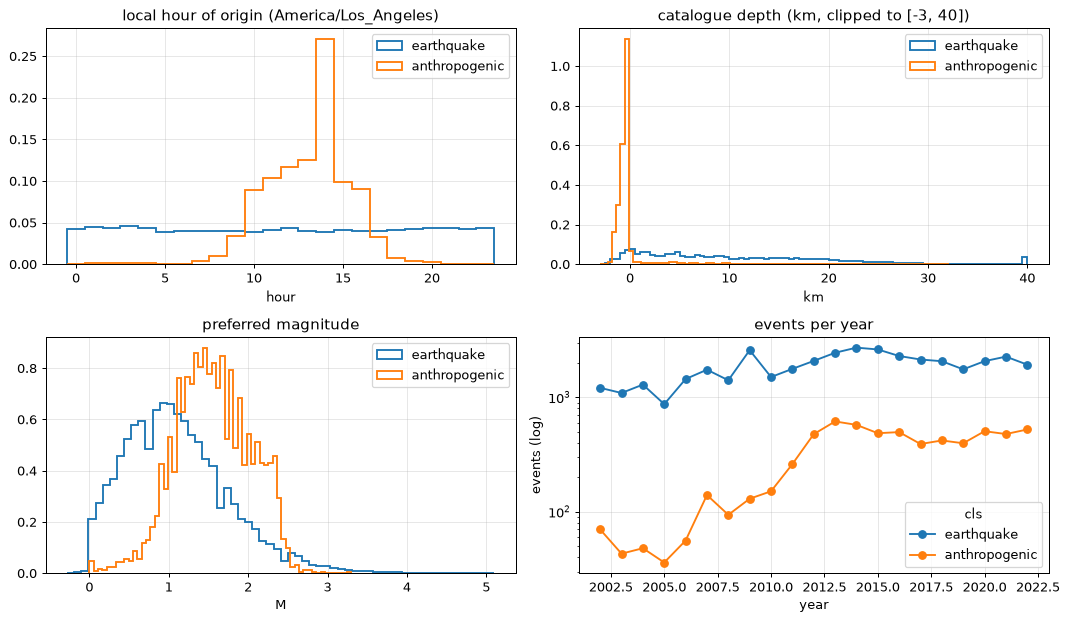

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for lab, color in [("earthquake", "tab:blue"), ("anthropogenic", "tab:orange")]:
    s = main[main.cls == lab]
    axes[0, 0].hist(s.local_hour, bins=np.arange(-0.5, 24.5), density=True, histtype="step", lw=1.5, color=color, label=lab)
    axes[0, 1].hist(s.dep.clip(-3, 40), bins=86, density=True, histtype="step", lw=1.5, color=color, label=lab)
    axes[1, 0].hist(s.mag, bins=60, density=True, histtype="step", lw=1.5, color=color, label=lab)
axes[0, 0].set(title="local hour of origin (America/Los_Angeles)", xlabel="hour"); axes[0, 1].set(title="catalogue depth (km, clipped to [-3, 40])", xlabel="km")
axes[1, 0].set(title="preferred magnitude", xlabel="M")
yearly = pd.crosstab(main.year, main.cls)[["earthquake", "anthropogenic"]]
yearly.plot(ax=axes[1, 1], marker="o", logy=True); axes[1, 1].set(title="events per year", ylabel="events (log)")
for ax in axes.flat[:3]: ax.legend()
fig.tight_layout()

Classes follow the proposed mapping in `configs/data.yaml` (`labels.class_map`).
**Observed:** anthropogenic events occur almost exclusively during local working hours and on
weekdays, at catalogue depths near/above sea level (fixed shallow depths), and their yearly count
rises sharply around 2011–2013 (earthquake counts do not). **Inferred:** time, depth and location
are near-perfect *label proxies* — they must never be model inputs (§12); the jump in explosion
counts most likely reflects labelling/cataloguing practice, i.e. **label-prior drift over time**
that a temporal split will expose. Magnitudes overlap.

## 8. Waveform inspection (exploration subset)

**Selection rule (documented, not cherry-picked):** among subset events that are *completely*
stored and have ≥ 3 stations, one event per label is drawn with `numpy.random.default_rng(SEED)`
(labels processed in the listed order); for exotic labels the minimum is 1 station. Stations are
shown in sorted `NET.STA` order (first 4). Amplitudes are raw counts; each panel has its own scale.

In [19]:
rng = np.random.default_rng(SEED)
def pick_event(meta, store, label_col, label, min_stations):
    complete = set(pnw.complete_event_ids(meta, store))
    counts = meta[meta.event_id.isin(complete)].groupby("event_id").agg(lab=(label_col, "first"), n=("trace_name", "size"))
    candidates = sorted(counts.index[(counts.lab == label) & (counts.n >= min_stations)])
    return rng.choice(candidates) if candidates else None

chosen = {}
for lab in ["eq", "px", "lf"]:
    chosen[("comcat", lab)] = pick_event(cc, cc_store, "source_type_pnsn_label", lab, 3)
for lab in ["surface event", "sonic boom"]:
    chosen[("exotic", lab)] = pick_event(ex, ex_store, "source_type", lab, 1)
chosen

{('comcat', 'eq'): np.str_('uw10727123'),
 ('comcat', 'px'): np.str_('uw61641106'),
 ('comcat', 'lf'): np.str_('uw61501723'),
 ('exotic', 'surface event'): np.str_('pnsn2779188'),
 ('exotic', 'sonic boom'): np.str_('pnsn1748343')}

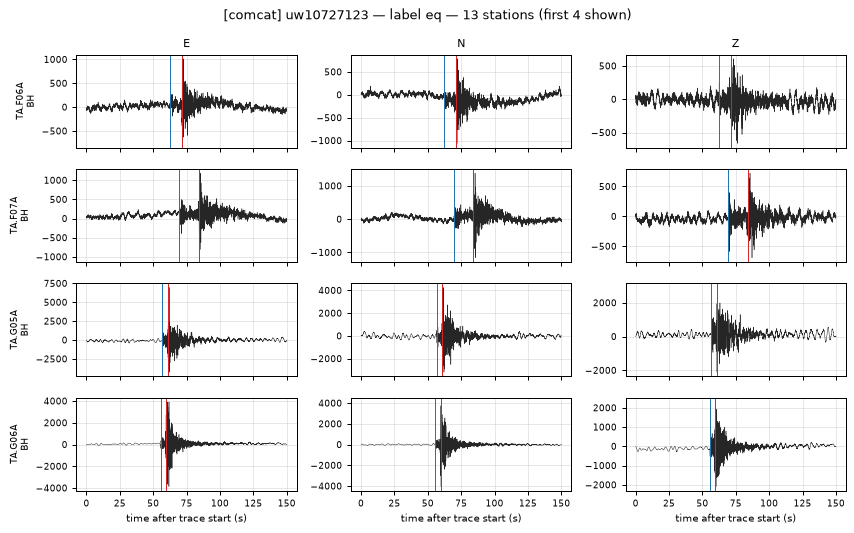

In [20]:
def show_event(collection, label):
    event_id = chosen[(collection, label)]
    meta, store, col = (cc, cc_store, "source_type_pnsn_label") if collection == "comcat" else (ex, ex_store, "source_type")
    event = pnw.rows_to_event(meta[meta.event_id == event_id], store, label_column=col)
    fig = plot_event_waveforms(event, max_stations=4)
    fig.suptitle(f"[{collection}] {event.event_id} — label {event.label} — {event.num_stations} stations (first 4 shown)", fontsize=10)
    return event

eq_event = show_event("comcat", "eq")

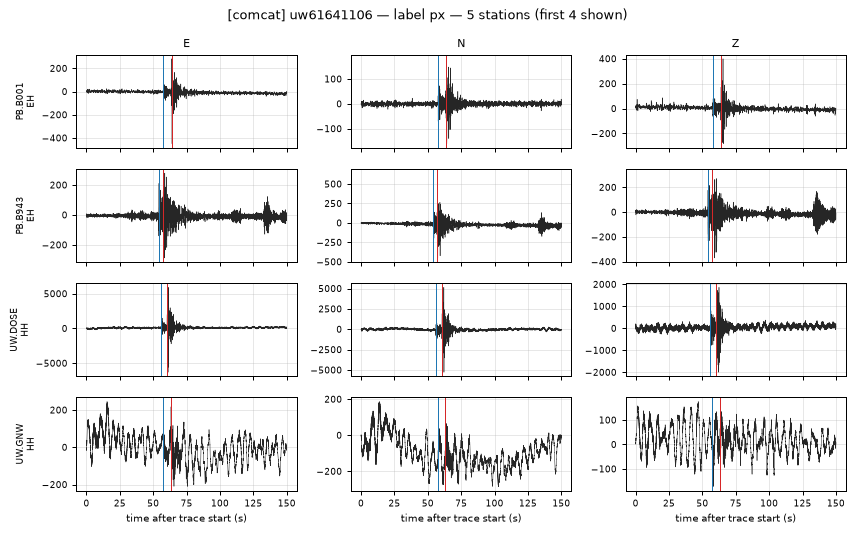

In [21]:
px_event = show_event('comcat', 'px')

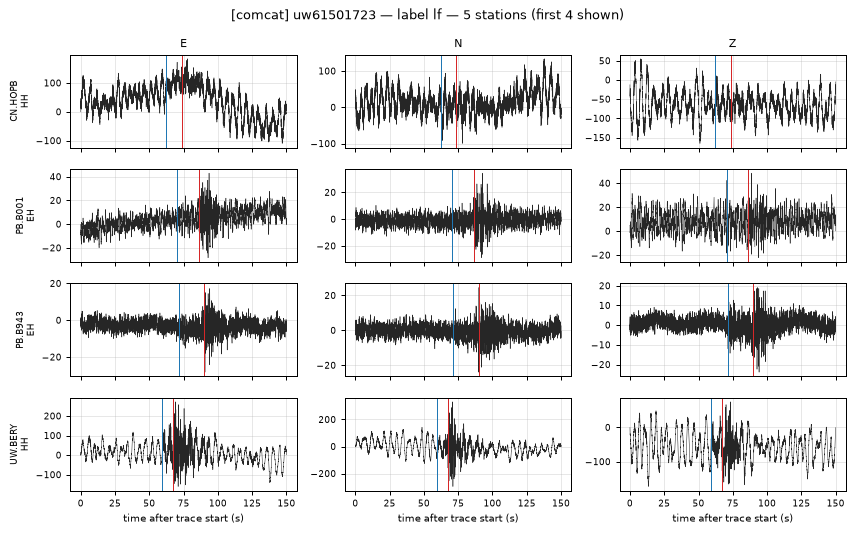

In [22]:
lf_event = show_event('comcat', 'lf')

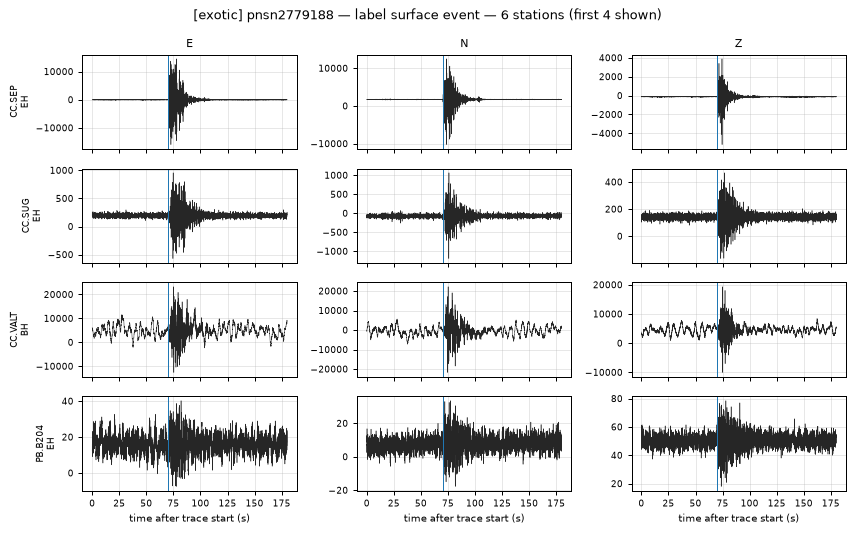

In [23]:
su_event = show_event('exotic', 'surface event')

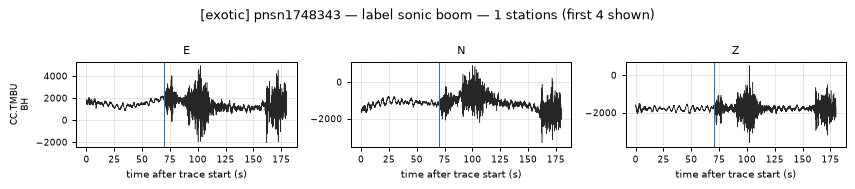

In [24]:
sb_event = show_event('exotic', 'sonic boom')

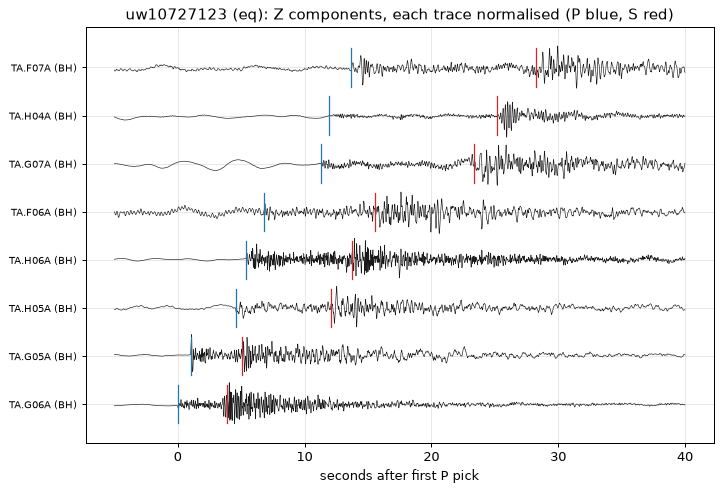

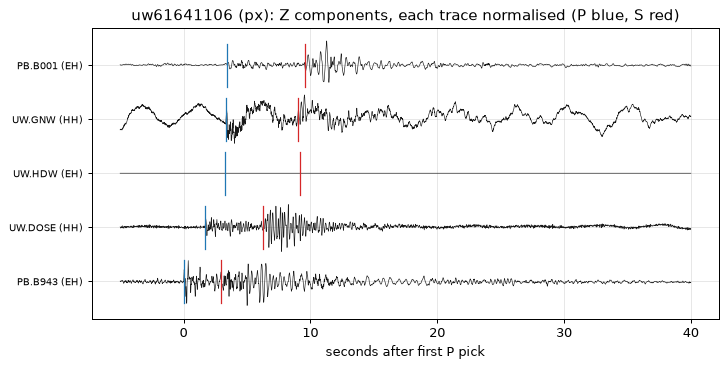

In [25]:
# Same event, several stations, zoomed around the P arrival of the nearest station (vertical component).
def vertical_section(event, span=(-5, 40), max_st=8):
    obs = sorted(event.observations, key=lambda o: o.p_arrival_time or o.waveform.start_time)[:max_st]
    t0 = obs[0].p_arrival_time
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(obs) + 1.2))
    for i, o in enumerate(obs):
        z = o.waveform.data[o.waveform.channels.index("Z")]
        t = np.arange(z.size) / o.waveform.sampling_rate + (o.waveform.start_time - t0).total_seconds()
        m = (t >= span[0]) & (t <= span[1])
        scale = np.abs(z[m]).max() or 1.0
        ax.plot(t[m], i + 0.45 * z[m] / scale, lw=0.5, color="0.1")
        for when, color in [(o.p_arrival_time, "tab:blue"), (o.s_arrival_time, "tab:red")]:
            if when is not None:
                x = (when - t0).total_seconds(); ax.plot([x, x], [i - 0.4, i + 0.4], color=color, lw=1)
    ax.set_yticks(range(len(obs)), [f"{o.station_id} ({o.metadata.get('station_channel_code')})" for o in obs], fontsize=8)
    ax.set(xlabel="seconds after first P pick", title=f"{event.event_id} ({event.label}): Z components, each trace normalised (P blue, S red)")
    return fig

vertical_section(eq_event); vertical_section(px_event);

## 9. Data quality (issues to hand to Phase 2 — nothing is cleaned here)

In [26]:
for name, rep in q.items():
    print(f"--- {name} metadata ---")
    for key in ["rows", "duplicate_trace_name", "duplicate_event_station", "picks", "sites_with_multiple_coordinates", "trace_missing_channel", "trace_has_offset", "snr_db"]:
        if key in rep: print(f"{key}: {rep[key]}")
    print("columns with missing values:", rep["missing_values"])
dups = inspection.possible_duplicate_events(cc)
print(f"\npossible duplicate ComCat events (different IDs, origins <= 2 s and <= 0.05 deg apart): {len(dups)}")
display(dups.head(13))

--- comcat metadata ---
rows: 178939
duplicate_trace_name: 0
duplicate_event_station: 0
picks: {'p_missing': 0, 's_missing': 0, 's_before_p': 0, 's_equals_p': 0}
sites_with_multiple_coordinates: 17
trace_missing_channel: {'0': 125461, '2': 49915, '1': 3563}
trace_has_offset: {'0': 177405, '1': 1534}
snr_db: {'all_components_nan': 0, 'max_component_below_0db': 4213}
columns with missing values: {'preferred_source_magnitude_uncertainty': 908, 'trace_P_arrival_uncertainty_s': 561, 'trace_P_polarity': 109, 'trace_S_onset': 43409, 'trace_P_onset': 44582, 'source_local_magnitude': 34056, 'source_local_magnitude_uncertainty': 34056, 'source_duration_magnitude': 367, 'source_duration_magnitude_uncertainty': 367, 'source_hand_magnitude': 177552}
--- exotic metadata ---
rows: 9267
duplicate_trace_name: 0
duplicate_event_station: 0
picks: {'p_missing': 120, 's_missing': 8607, 's_before_p': 0, 's_equals_p': 26}
sites_with_multiple_coordinates: 3
snr_db: {'all_components_nan': 0, 'max_component_bel

,event_a,event_b,dt_s
0,uw10616113,uw60046208,1.99
1,uw60048708,uw60731741,0.08
2,uw60906051,uw60094313,1.53
3,uw60943327,uw60103408,1.13
4,uw61208281,uw61208286,0.19
5,uw61249896,uw60132508,1.52
6,uw61529961,uw61500413,1.29
7,uw61545062,uw61545057,0.01
8,uw61558557,uw61558562,0.07
9,uw61625752,uw61625757,0.02


In [27]:
wq_ex = inspection.waveform_quality_table(ex, ex_store)
for name, table in [("comcat subset", wq), ("exotic subset", wq_ex)]:
    t = table.groupby("trace_name").agg(nan=("n_nan", "max"), flat=("flat_nonzero", "max"), at_peak=("n_at_peak", "max"))
    nz = table[~table.all_zero].groupby("trace_name").longest_zero_run.max()
    print(f"{name}: traces {len(t)} | with NaN {int((t.nan > 0).sum())} | flat non-zero component {int(t.flat.sum())} | "
          f">=10 samples at peak (clipping indicator) {int((t.at_peak >= 10).sum())} | zero-run >= 100 samples on a live component {int((nz >= 100).sum())}")

comcat subset: traces 4019 | with NaN 0 | flat non-zero component 0 | >=10 samples at peak (clipping indicator) 0 | zero-run >= 100 samples on a live component 0
exotic subset: traces 1133 | with NaN 0 | flat non-zero component 0 | >=10 samples at peak (clipping indicator) 0 | zero-run >= 100 samples on a live component 0


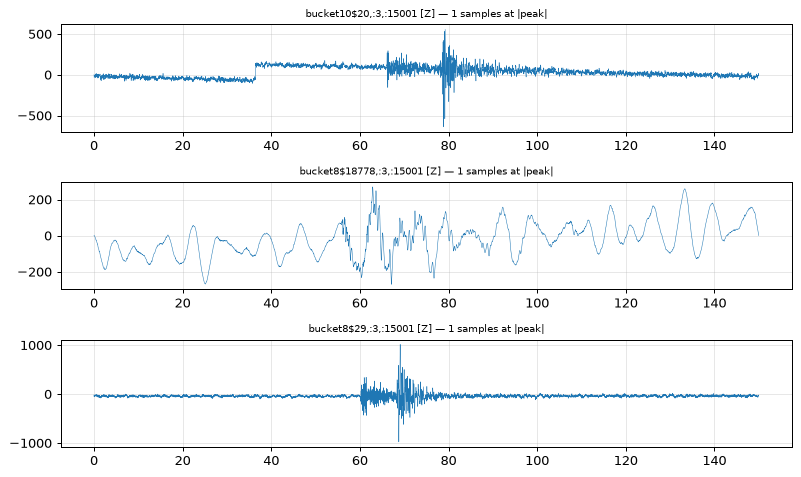

In [28]:
# Visual check of the clipping indicator: the subset traces with the most samples at their peak value.
top = wq.sort_values("n_at_peak", ascending=False).drop_duplicates("trace_name").head(3)
fig, axes = plt.subplots(len(top), 1, figsize=(9, 1.8 * len(top)), squeeze=False)
for ax, (_, r) in zip(axes[:, 0], top.iterrows()):
    x = cc_store.get(r.trace_name)[cc_store.component_order.index(r.component)]
    ax.plot(np.arange(x.size) / 100, x, lw=0.4); ax.set_title(f"{r.trace_name} [{r.component}] — {r.n_at_peak} samples at |peak|", fontsize=8)
fig.tight_layout()

Also **documented** by the authors and visible in `trace_has_offset`: steps/offsets where
triggered and continuous data overlap, and clipped records kept as-is. **Documented (Nov 2025
metadata update):** 4,970 ComCat samples containing undocumented additional events were removed from
the metadata (waveforms remain in the HDF5 file).

## 10. OOD feasibility

In [29]:
ood_rows = []
for lab in labels_cfg["ood_labels"]["comcat"]:
    n = n_cc[lab_cc == lab]; ood_rows.append(("comcat", lab, len(n), int((n >= 2).sum()), int((n >= 3).sum()), int((n >= 4).sum())))
for lab in labels_cfg["ood_labels"]["exotic"]:
    n = n_ex[lab_ex == lab]; ood_rows.append(("exotic", lab, len(n), int((n >= 2).sum()), int((n >= 3).sum()), int((n >= 4).sum())))
pd.DataFrame(ood_rows, columns=["collection", "label", "events", ">=2 stations", ">=3 stations", ">=4 stations"])

,collection,label,events,>=2 stations,>=3 stations,>=4 stations
0,comcat,lf,265,192,129,78
1,comcat,su,24,19,11,6
2,comcat,sn,2,2,0,0
3,exotic,surface event,5425,1211,722,530
4,exotic,sonic boom,111,38,29,19
5,exotic,thunder,120,15,7,3
6,exotic,plane crash,1,1,1,0


**Observed:** scientifically distinct unfamiliar sources exist in the same network: low-frequency
events (`lf`, volcanic/glacial), surface events (mass movements), sonic booms and thunder
(atmospheric). They are **not** in the proposed training classes (Decision 011), and `lf`/`su`/`sn`
are hidden inside ComCat's `earthquake` category — using `source_type` instead of the PNSN label
would leak them into training. **Limitations:** multi-station OOD events are few (see table);
exotic events have no origin information; exotic windows are pick-aligned (§4 shortcut);
exotic recordings over-represent the volcano network (`CC`), so station identity could act as
an OOD shortcut; surface-event labels may contain errors (1.5–8.4 % estimated in related work).

## 11. Inputs to the split design (full ComCat metadata)

In [30]:
anthro = [k for k, v in labels_cfg["class_map"].items() if v == "anthropogenic"]
def cell_id(df):
    return (df.lat / 0.1).round().astype(int).astype(str) + "_" + (df.lon / 0.1).round().astype(int).astype(str)
a = ev_cls[ev_cls.lab.isin(anthro)]
cells = cell_id(a)
vc = cells.value_counts()
eq_cells = set(cell_id(ev_cls[ev_cls.lab == "eq"]))
print(f"anthropogenic cells that also contain earthquakes: {len(set(cells) & eq_cells)} of {vc.size}")
print(f"anthropogenic ({'+'.join(anthro)}) events: {len(a)} in {vc.size} 0.1-degree cells; {(vc >= 20).sum()} cells with >= 20 events hold {vc[vc >= 20].sum() / len(a):.1%}; top-10 cells hold {vc.head(10).sum() / len(a):.1%}")
sup = cc[cc.source_type_pnsn_label.isin(list(labels_cfg["class_map"]))]      # supervised-class traces only
sid = sup.station_network_code + "." + sup.station_code
share = pd.crosstab(sid, sup.source_type_pnsn_label.isin(anthro))
share = share[share.sum(axis=1) >= 50]
frac = share[True] / share.sum(axis=1)
print(f"stations with >= 50 traces: {len(share)}; anthropogenic-trace share quantiles (10/50/90%): {frac.quantile([.1, .5, .9]).round(3).tolist()}; stations with share > 0.5: {int((frac > 0.5).sum())}")
region = np.where(ev_cls.lat >= 46.0, "WA", "OR") + np.where(ev_cls.lon >= -121.0, "-east", "-west")
display(pd.crosstab(region, ev_cls.lab)[["eq", "px", "ex", "qb", "lf"]])

anthropogenic cells that also contain earthquakes: 663 of 1156
anthropogenic (px+ex+qb) events: 6396 in 1156 0.1-degree cells; 47 cells with >= 20 events hold 48.8%; top-10 cells hold 30.4%


stations with >= 50 traces: 345; anthropogenic-trace share quantiles (10/50/90%): [0.009, 0.069, 0.341]; stations with share > 0.5: 15


lab,eq,px,ex,qb,lf
row_0,,,,,
OR-east,1373,197,1,0,0
OR-west,5416,1892,9,0,72
WA-east,5460,2007,5,0,0
WA-west,27117,2266,15,4,193


**Implications (Inferred):** explosions repeat at a limited set of sites and some stations record
mostly explosions → random event-level splits would test memorisation of sites/paths; time
structure (swarms, labelling drift) argues for temporal blocking; regional blocks are feasible for
geographic-generalisation tests (every region has both classes). The proposed split is documented
in `PROJECT_CONTEXT.md` → *PROPOSED DATA SPLIT*.

## 12. Summary of findings

See `PROJECT_CONTEXT.md` → *DATA EXPLORATION FINDINGS*, *DATA QUALITY ISSUES*, *OOD STRATEGY* and
*PROPOSED DATA SPLIT* for the consolidated, versioned write-up. The machine-readable counterpart is
`<data_root>/processed/dataset_manifest.json` (from `scripts/inspect_data.py`).

In [31]:
cc_store.close(); ex_store.close()